In [2]:
import pandas as pd

df = pd.read_csv("../data/raw/superstore_sales.csv")

df.head()

,Order Date,Region,State,Category,Sub-Category,Segment,Sales,Profit,Quantity
0,11/8/2016,South,Kentucky,Furniture,Bookcases,Consumer,261.9600,41.9136,2
1,11/8/2016,South,Kentucky,Furniture,Chairs,Consumer,731.9400,219.5820,3
2,6/12/2016,West,California,Office Supplies,Labels,Corporate,14.6200,6.8714,2
3,10/11/2015,South,Florida,Furniture,Tables,Consumer,957.5775,-383.0310,5
4,10/11/2015,South,Florida,Office Supplies,Storage,Consumer,22.3680,2.5164,2


In [3]:
df.shape

(9994, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order Date    9994 non-null   str    
 1   Region        9994 non-null   str    
 2   State         9994 non-null   str    
 3   Category      9994 non-null   str    
 4   Sub-Category  9994 non-null   str    
 5   Segment       9994 non-null   str    
 6   Sales         9994 non-null   float64
 7   Profit        9994 non-null   float64
 8   Quantity      9994 non-null   int64  
dtypes: float64(2), int64(1), str(6)
memory usage: 702.8 KB


In [5]:
df.duplicated().sum()

np.int64(2)

In [6]:
df = df.drop_duplicates()

In [7]:
df.shape

(9992, 9)

In [41]:
df.info()

<class 'pandas.DataFrame'>
Index: 9992 entries, 0 to 9993
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order Date    9992 non-null   datetime64[us]
 1   Region        9992 non-null   str           
 2   State         9992 non-null   str           
 3   Category      9992 non-null   str           
 4   Sub-Category  9992 non-null   str           
 5   Segment       9992 non-null   str           
 6   Sales         9992 non-null   float64       
 7   Profit        9992 non-null   float64       
 8   Quantity      9992 non-null   int64         
 9   Month         9992 non-null   period[M]     
dtypes: datetime64[us](1), float64(2), int64(1), period[M](1), str(5)
memory usage: 858.7 KB


In [8]:
df.isnull().sum()

Order Date      0
Region          0
State           0
Category        0
Sub-Category    0
Segment         0
Sales           0
Profit          0
Quantity        0
dtype: int64

In [9]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [10]:
df.dtypes

Order Date      datetime64[us]
Region                     str
State                      str
Category                   str
Sub-Category               str
Segment                    str
Sales                  float64
Profit                 float64
Quantity                 int64
dtype: object

In [11]:
df.describe()

,Order Date,Sales,Profit,Quantity
count,9992,9992.000000,9992.000000,9992.000000
mean,2016-04-30 02:36:47.846277,229.875356,28.663765,3.789932
min,2014-01-03 00:00:00,0.444000,-6599.978000,1.000000
25%,2015-05-23 00:00:00,17.280000,1.732125,2.000000
50%,2016-06-26 00:00:00,54.490000,8.671250,3.000000
75%,2017-05-14 00:00:00,209.940000,29.364000,5.000000
max,2017-12-30 00:00:00,22638.480000,8399.976000,14.000000
std,NaN,623.303203,234.283033,2.225188


In [12]:
df["Category"].value_counts()

Category
Office Supplies    6026
Furniture          2119
Technology         1847
Name: count, dtype: int64

In [13]:
df["Sub-Category"].value_counts()

Sub-Category
Binders        1523
Paper          1370
Furnishings     956
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          616
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64

In [14]:
df[["Sales", "Profit", "Quantity"]].sum()

Sales       2.296915e+06
Profit      2.864083e+05
Quantity    3.786900e+04
dtype: float64

In [15]:
df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

Category
Technology         836154.0330
Furniture          741713.4953
Office Supplies    719047.0320
Name: Sales, dtype: float64

In [16]:
df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18462.5924
Name: Profit, dtype: float64

In [17]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Sales"].sum()

monthly_sales

Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28013.9730
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28760.3970
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160
2017-

In [18]:
monthly_sales.idxmax(), monthly_sales.max()

(Period('2017-11', 'M'), np.float64(118447.825))

In [19]:
df.groupby("Category")["Quantity"].sum().sort_values(ascending=False)

Category
Office Supplies    22906
Furniture           8024
Technology          6939
Name: Quantity, dtype: int64

In [20]:
df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).head(10)

Sub-Category
Phones         330007.0540
Chairs         328167.7310
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Name: Sales, dtype: float64

In [21]:
df.groupby("Sub-Category")["Profit"].sum().sort_values()

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13058.4044
Appliances     18138.0054
Storage        21278.8264
Chairs         26602.2251
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64

In [22]:
df.groupby("Sub-Category")["Profit"].sum().sort_values(ascending=False).head(10)

Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          34053.5693
Binders        30221.7633
Chairs         26602.2251
Storage        21278.8264
Appliances     18138.0054
Furnishings    13058.4044
Envelopes       6964.1767
Name: Profit, dtype: float64

In [23]:
df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

Region
West       725457.8245
East       678499.8680
Central    501239.8908
South      391716.9770
Name: Sales, dtype: float64

In [24]:
df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)

Segment
Consumer       1.161401e+06
Corporate      7.061414e+05
Home Office    4.293718e+05
Name: Sales, dtype: float64

In [25]:
profit_margin = (df["Profit"].sum() / df["Sales"].sum()) * 100
profit_margin

np.float64(12.469264040130087)

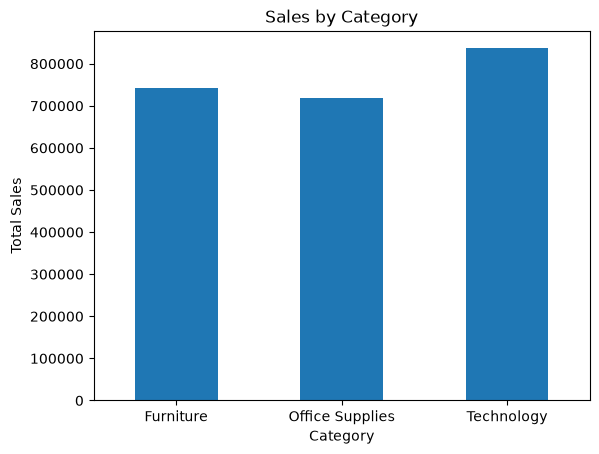

In [26]:
import matplotlib.pyplot as plt

category_sales = df.groupby("Category")["Sales"].sum()

category_sales.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()

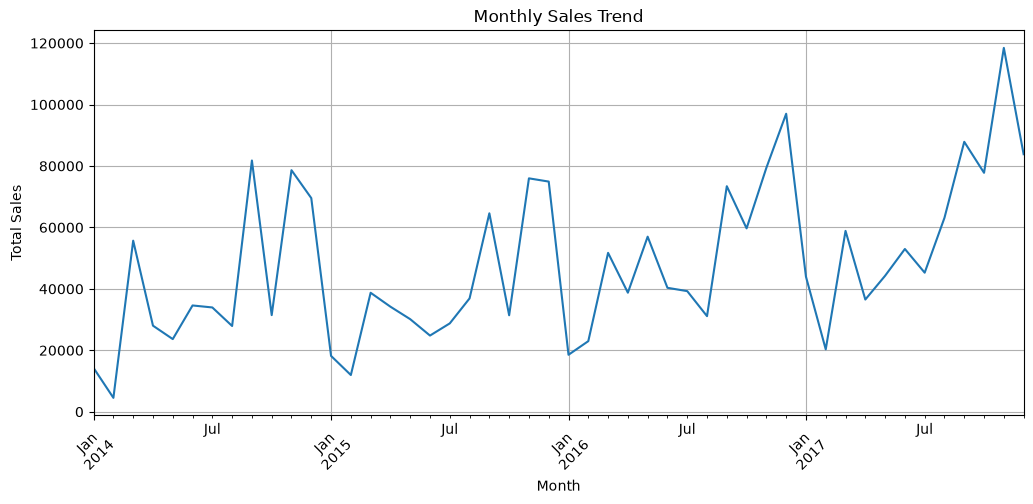

In [27]:
monthly_sales.plot(kind="line", figsize=(12, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

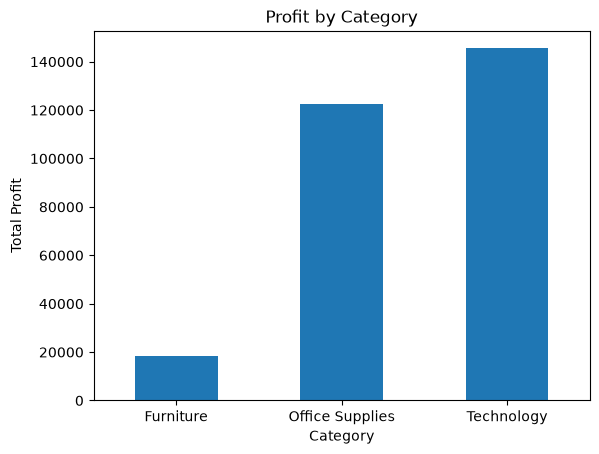

In [28]:
category_profit = df.groupby("Category")["Profit"].sum()

category_profit.plot(kind="bar")

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.show()

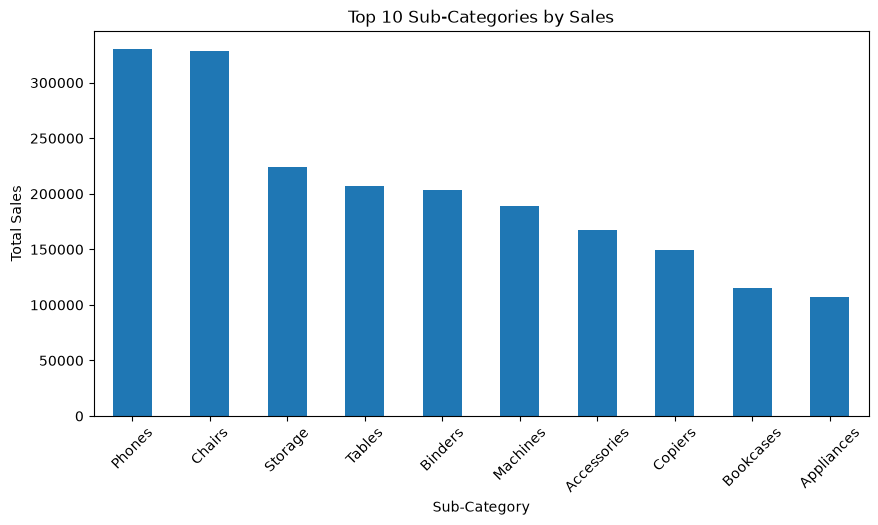

In [29]:
top_subcategories = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).head(10)

top_subcategories.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Sub-Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

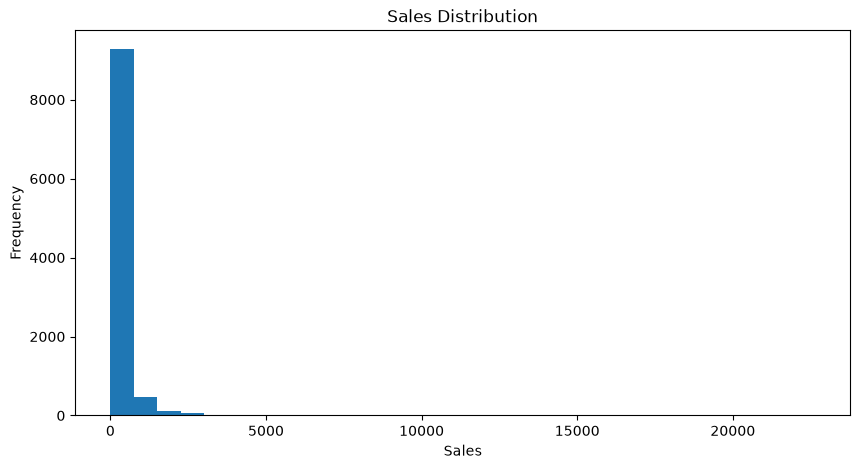

In [30]:
df["Sales"].plot(kind="hist", bins=30, figsize=(10, 5))

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

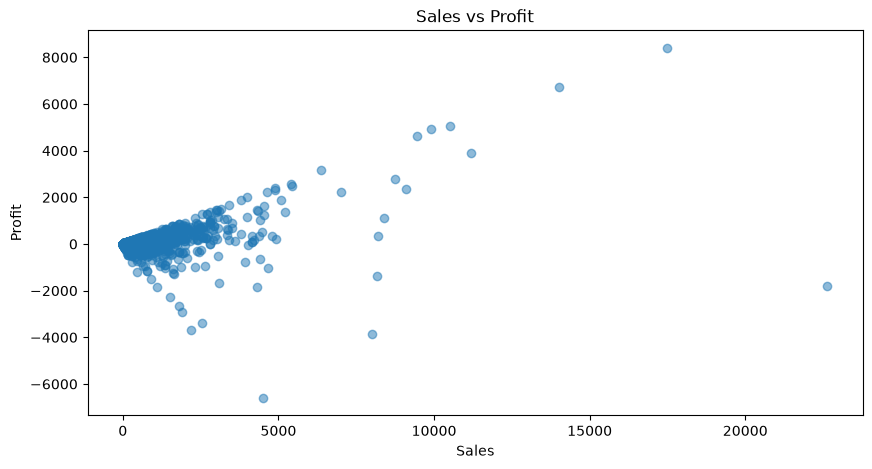

In [31]:
plt.figure(figsize=(10, 5))

plt.scatter(df["Sales"], df["Profit"], alpha=0.5)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

In [32]:
df.to_csv("../data/cleaned/superstore_sales_cleaned.csv", index=False)

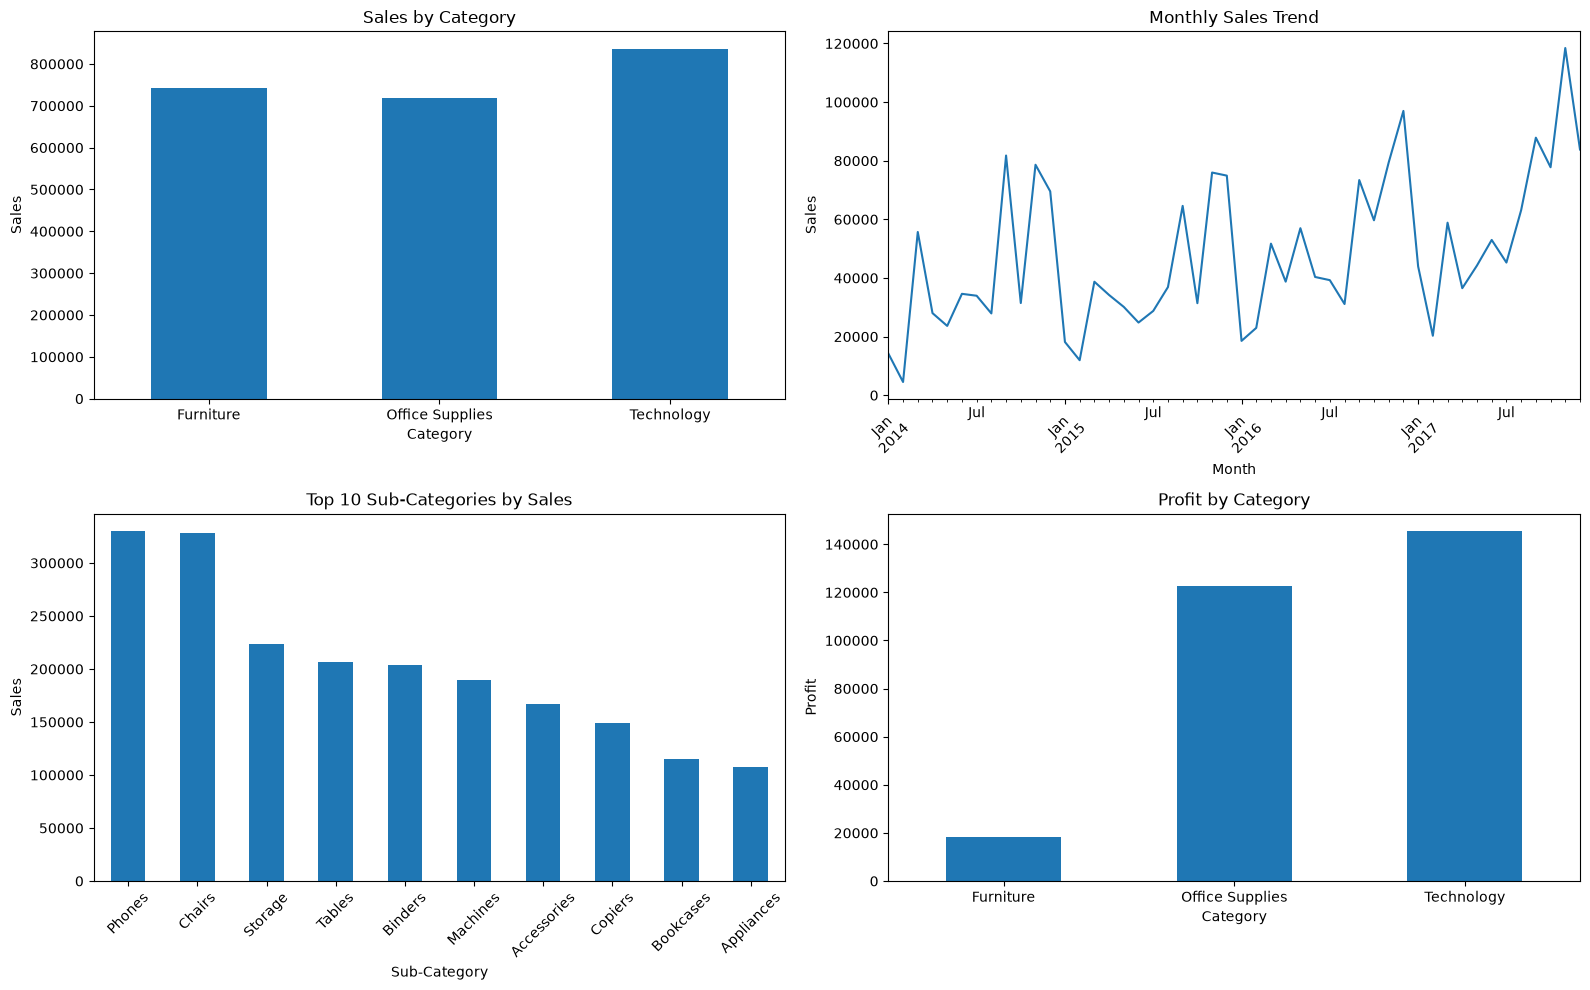

In [33]:
fig = plt.figure(figsize=(16, 10))

# 1. Sales by Category
ax1 = plt.subplot(2, 2, 1)
category_sales.plot(kind="bar", ax=ax1)
ax1.set_title("Sales by Category")
ax1.set_xlabel("Category")
ax1.set_ylabel("Sales")
ax1.tick_params(axis="x", rotation=0)

# 2. Monthly Sales Trend
ax2 = plt.subplot(2, 2, 2)
monthly_sales.plot(kind="line", ax=ax2)
ax2.set_title("Monthly Sales Trend")
ax2.set_xlabel("Month")
ax2.set_ylabel("Sales")
ax2.tick_params(axis="x", rotation=45)

# 3. Top 10 Sub-Categories
ax3 = plt.subplot(2, 2, 3)
top_subcategories.plot(kind="bar", ax=ax3)
ax3.set_title("Top 10 Sub-Categories by Sales")
ax3.set_xlabel("Sub-Category")
ax3.set_ylabel("Sales")
ax3.tick_params(axis="x", rotation=45)

# 4. Profit by Category
ax4 = plt.subplot(2, 2, 4)
category_profit.plot(kind="bar", ax=ax4)
ax4.set_title("Profit by Category")
ax4.set_xlabel("Category")
ax4.set_ylabel("Profit")
ax4.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


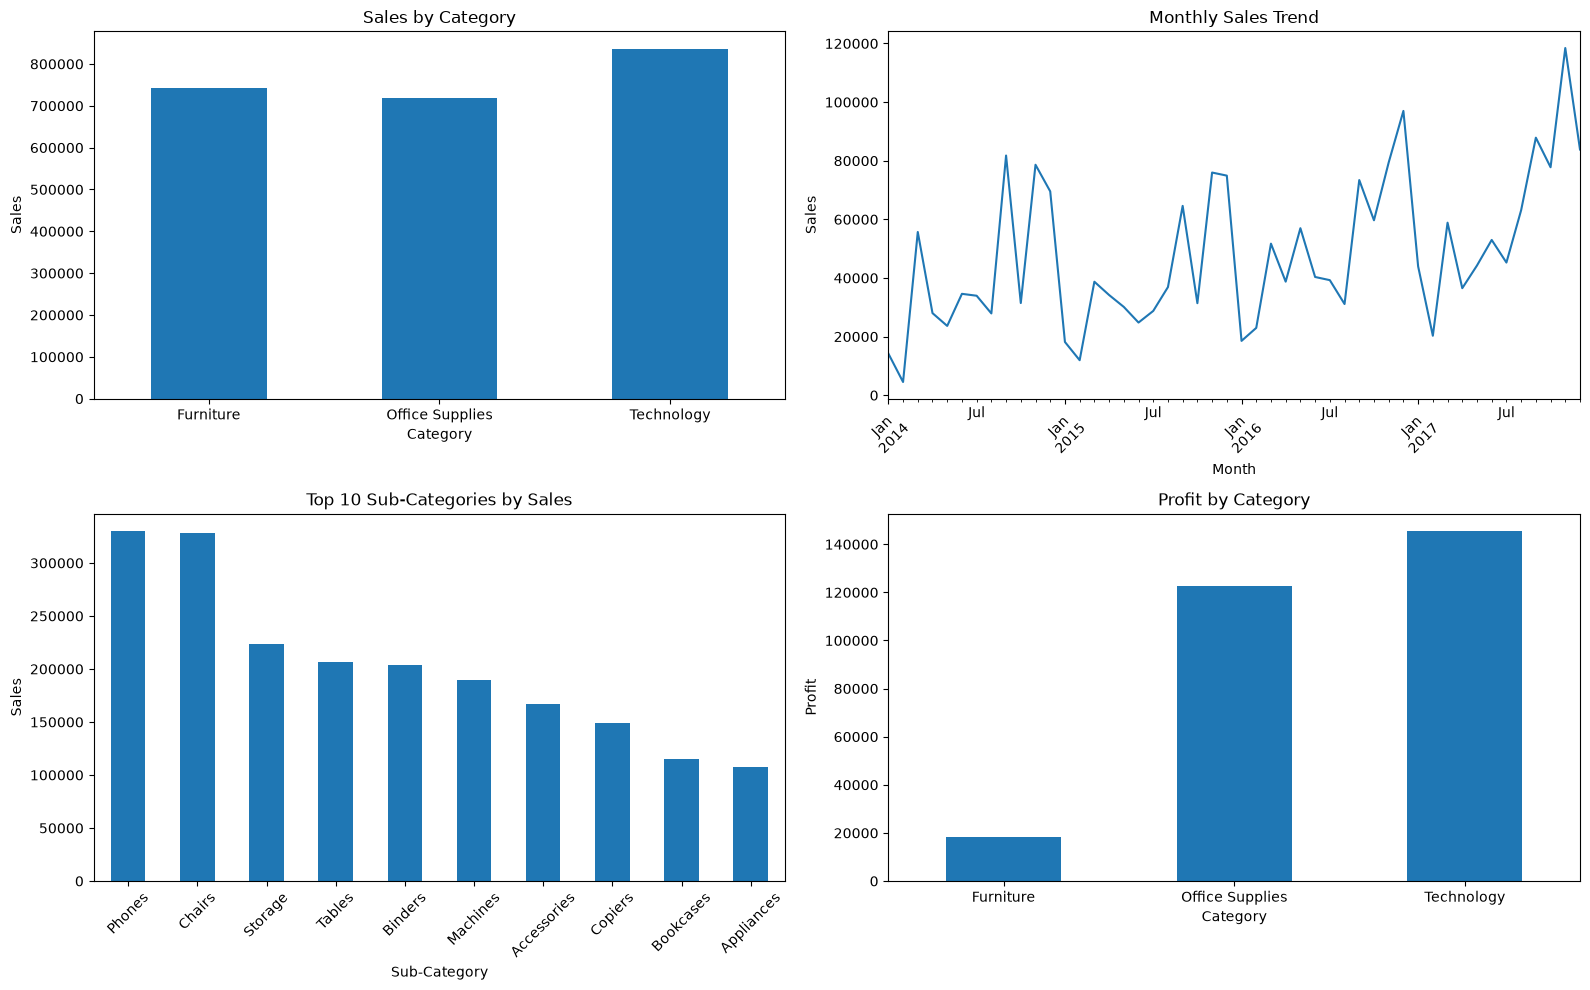

In [34]:
fig = plt.figure(figsize=(16, 10))

# 1. Sales by Category
ax1 = plt.subplot(2, 2, 1)
category_sales.plot(kind="bar", ax=ax1)
ax1.set_title("Sales by Category")
ax1.set_xlabel("Category")
ax1.set_ylabel("Sales")
ax1.tick_params(axis="x", rotation=0)

# 2. Monthly Sales Trend
ax2 = plt.subplot(2, 2, 2)
monthly_sales.plot(kind="line", ax=ax2)
ax2.set_title("Monthly Sales Trend")
ax2.set_xlabel("Month")
ax2.set_ylabel("Sales")
ax2.tick_params(axis="x", rotation=45)

# 3. Top 10 Sub-Categories
ax3 = plt.subplot(2, 2, 3)
top_subcategories.plot(kind="bar", ax=ax3)
ax3.set_title("Top 10 Sub-Categories by Sales")
ax3.set_xlabel("Sub-Category")
ax3.set_ylabel("Sales")
ax3.tick_params(axis="x", rotation=45)

# 4. Profit by Category
ax4 = plt.subplot(2, 2, 4)
category_profit.plot(kind="bar", ax=ax4)
ax4.set_title("Profit by Category")
ax4.set_xlabel("Category")
ax4.set_ylabel("Profit")
ax4.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("../reports/retail_sales_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

In [35]:
with pd.ExcelWriter("../reports/retail_sales_report.xlsx", engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Cleaned Data", index=False)
    category_sales.to_frame("Total Sales").to_excel(writer, sheet_name="Category Sales")
    category_profit.to_frame("Total Profit").to_excel(writer, sheet_name="Category Profit")
    monthly_sales.to_frame("Monthly Sales").to_excel(writer, sheet_name="Monthly Sales")
    top_subcategories.to_frame("Total Sales").to_excel(writer, sheet_name="Top Sub-Categories")

In [38]:
!python -m pip install reportlab

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   -------------------------------

In [39]:
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.pagesizes import A4

pdf_path = "../reports/retail_sales_report.pdf"

doc = SimpleDocTemplate(pdf_path, pagesize=A4)
styles = getSampleStyleSheet()

content = []

content.append(Paragraph("Retail Sales Analysis Report", styles["Title"]))
content.append(Spacer(1, 20))

content.append(Paragraph(f"Total Sales: {df['Sales'].sum():,.2f}", styles["Normal"]))
content.append(Paragraph(f"Total Profit: {df['Profit'].sum():,.2f}", styles["Normal"]))
content.append(Paragraph(f"Profit Margin: {profit_margin:.2f}%", styles["Normal"]))
content.append(Paragraph(f"Total Quantity Sold: {df['Quantity'].sum():,}", styles["Normal"]))
content.append(Paragraph(f"Number of Records: {len(df):,}", styles["Normal"]))

content.append(Spacer(1, 15))

content.append(Paragraph(
    f"Highest Sales Month: {monthly_sales.idxmax()}",
    styles["Normal"]
))

content.append(Paragraph(
    f"Highest Monthly Sales: {monthly_sales.max():,.2f}",
    styles["Normal"]
))

content.append(Spacer(1, 15))

content.append(Paragraph(
    "Data cleaning: 2 duplicate records were removed.",
    styles["Normal"]
))

doc.build(content)

print("PDF report created successfully!")

PDF report created successfully!
